# Panel Analysis: The Same Voters in 2020, 2022, and 2024

The 2020–2024 CES panel re-interviewed 6,175 people across three waves. It answers three questions the cross-section could not:

1. **Within-person perception change.** The partisan flip in notebook 06 compared different samples. Here it is the same respondents rating the economy under Trump (2020), under Biden at the inflation peak (2022), and under Biden in 2024. Composition cannot explain a within-person change.
2. **Timing.** The cross-sectional gap → switching result could not rule out reverse causation: a decided switcher rates the economy badly because of the decision. A 2022 rating cannot be a rationalization of a 2024 vote. Does perception in 2022 predict switching in 2024?
3. **Demobilization, validated.** Part 2 inferred turnout loss from county aggregates. The panel has voter-file-validated turnout for 2020, 2022, and 2024 — who among 2020 Biden voters did not vote in 2024, by record rather than self-report.

**Power.** 1,684 Biden 2020 voters have a 2024 major-party vote; 39 switched to Trump. The timing test can support a monotonic pattern and a model with a few controls, not more.

**Inputs:** `data/raw/ces_panel/ces_panel_wide.csv`, `ces_panel_long.csv` (from `ces_panel_pull.py`), `data/processed/county_covariates.csv`

**Weights.** `commonweight_24` for perception items (all 6,175); `commonpostweight_24` for anything using the 2024 post-election vote (4,015 completed the post wave). Validated turnout uses `commonpostweight_24` where available, `commonweight_24` otherwise.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR     = Path('../data/raw')
PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

w = pd.read_csv(RAW_DIR / 'ces_panel' / 'ces_panel_wide.csv', low_memory=False)
print(f'Panelists: {len(w):,}   completed 2024 post wave: {w["commonpostweight_24"].notna().sum():,}')

# Perception per wave, signed (+2 much better ... -2 much worse); 'not sure' -> NaN
for yr in [2020, 2022, 2024]:
    w[f'perc_{yr}'] = 3 - w[f'econ_retro_{yr}'].where(w[f'econ_retro_{yr}'].between(1, 5))
    w[f'income_{yr}'] = 3 - w[f'hh_income_retro_{yr}'].where(w[f'hh_income_retro_{yr}'].between(1, 5))
for yr in [2022, 2024]:
    w[f'prices_{yr}'] = 3 - w[f'prices_retro_{yr}'].where(w[f'prices_retro_{yr}'].between(1, 5))   # +2 = rose a lot

# Party ID fixed at the 2020 baseline (pre-treatment for everything that follows)
w['pid7_20'] = w['pid7_2020'].where(w['pid7_2020'].between(1, 7))
w['pid3_20'] = pd.cut(w['pid7_20'], [0, 3, 4, 7], labels=['Dem', 'Ind', 'Rep'])
w['college'] = (w['educ_2020'] >= 5).astype(int)
w['age']     = 2024 - w['birthyr']
w['age_z']   = (w['age'] - w['age'].mean()) / w['age'].std()
w['white']   = ((w['race'] == 1) & (w['hispanic'] != 1)).astype(int)

# 2022 media diet (pre-decision): network items asked only of TV-news watchers; non-watchers coded 0
w['fox_22']   = (w['q300b_5_2022'] == 1).astype(int)
w['msnbc_22'] = (w['q300b_6_2022'] == 1).astype(int)
w['cnn_22']   = (w['q300b_4_2022'] == 1).astype(int)
w['tv_22']    = (w['q300_2_2022'] == 1).astype(int)
w['paper_22'] = (w['q300_3_2022'] == 1).astype(int)

# County economic record (2024 county; 12% moved between 2020 and 2024 - flagged, not dropped)
cov = pd.read_csv(PROC_DIR / 'county_covariates.csv')
w['moved'] = (w['county_fips_2020'] != w['county_fips_2024']).astype(int)
w = w.merge(cov[['county_fips', 'real_pay_pct_chg_2020_2024', 'private_emp_pct_chg_2020_2024', 'unemp_rate',
                 'white_nocollege', 'college_share', 'log_income', 'dem_share_2020', 'swing_2024']]
            .rename(columns={'county_fips': 'county_fips_2024'}), on='county_fips_2024', how='left')
for v in ['real_pay_pct_chg_2020_2024', 'private_emp_pct_chg_2020_2024', 'unemp_rate']:
    mu = wmean(cov[v], cov['population']); sd = np.sqrt(wmean((cov[v] - mu) ** 2, cov['population']))
    w[v + '_z'] = (w[v] - mu) / sd

print(f'Moved county 2020->2024: {w["moved"].sum():,} ({w["moved"].mean():.1%})   county economic record matched: {w["real_pay_pct_chg_2020_2024"].notna().mean():.1%}')
print(f'2020 vote (reported in 2020): D {int((w["presvote_post_party_2020"] == "D").sum()):,}  R {int((w["presvote_post_party_2020"] == "R").sum()):,}')

Panelists: 6,175   completed 2024 post wave: 4,015
Moved county 2020->2024: 741 (12.0%)   county economic record matched: 98.7%
2020 vote (reported in 2020): D 3,064  R 2,397


## 1. The partisan flip, within person

Same respondents, party ID as of 2020, three ratings of "the nation's economy over the past year". 

Weighted mean perceived economy by 2020 party ID (same respondents):
       Dem   Ind   Rep   All
wave                        
2020 -1.52 -0.98  0.08 -0.80
2022 -0.49 -1.18 -1.71 -1.10
2024  0.34 -0.81 -1.36 -0.54

Within-person change 2020 -> 2024 (Trump incumbent -> Biden incumbent), by 2020 party ID:
  Dem   mean change +1.88   moved 2+ points toward own-party-incumbent: 60.8%
  Ind   mean change +0.22   moved 2+ points toward own-party-incumbent: 12.7%
  Rep   mean change -1.43   moved 2+ points toward own-party-incumbent: 45.7%


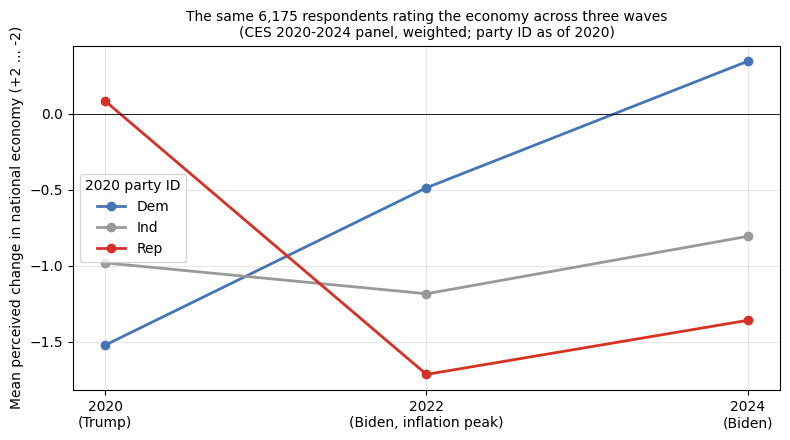

In [2]:
wt = w['commonweight_24']
flip = pd.DataFrame({yr: {p: wmean(w.loc[w['pid3_20'] == p, f'perc_{yr}'], wt[w['pid3_20'] == p]) for p in ['Dem', 'Ind', 'Rep']}
                     for yr in [2020, 2022, 2024]}).T
flip['All'] = [wmean(w[f'perc_{yr}'], wt) for yr in [2020, 2022, 2024]]
flip.index.name = 'wave'
print('Weighted mean perceived economy by 2020 party ID (same respondents):')
print(flip.round(2))
print()
print('Within-person change 2020 -> 2024 (Trump incumbent -> Biden incumbent), by 2020 party ID:')
w['d_perc_20_24'] = w['perc_2024'] - w['perc_2020']
w['d_perc_20_22'] = w['perc_2022'] - w['perc_2020']
w['d_perc_22_24'] = w['perc_2024'] - w['perc_2022']
for p in ['Dem', 'Ind', 'Rep']:
    s = w[w['pid3_20'] == p]
    print(f'  {p:4s}  mean change {wmean(s["d_perc_20_24"], s["commonweight_24"]):+.2f}   '
          f'moved 2+ points toward own-party-incumbent: '
          f'{wmean(((s["d_perc_20_24"] >= 2) if p == "Dem" else (s["d_perc_20_24"] <= -2)).astype(float), s["commonweight_24"]):.1%}')

fig, ax = plt.subplots(figsize=(8, 4.5))
for p, color in [('Dem', '#4575b4'), ('Ind', '#999999'), ('Rep', '#d73027')]:
    ax.plot([2020, 2022, 2024], flip.loc[[2020, 2022, 2024], p], marker='o', lw=2, color=color, label=p)
ax.axhline(0, color='black', lw=0.6)
ax.set_xticks([2020, 2022, 2024]); ax.set_xticklabels(['2020\n(Trump)', '2022\n(Biden, inflation peak)', '2024\n(Biden)'])
ax.set_ylabel('Mean perceived change in national economy (+2 ... -2)')
ax.set_title('The same 6,175 respondents rating the economy across three waves\n(CES 2020-2024 panel, weighted; party ID as of 2020)', fontsize=10)
ax.legend(title='2020 party ID'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'panel_partisan_flip.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Does local reality register within person?

First differences remove everything fixed about a person. If the county's 2020→2024 real pay change predicts a respondent's 2020→2024 change in rating, local reality registers; the cross-section said it does not.

In [3]:
fd = w.dropna(subset=['d_perc_20_24', 'pid7_20', 'real_pay_pct_chg_2020_2024_z']).copy()
actual = 'real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z + unemp_rate_z'
clus = {'groups': fd['county_fips_2024']}
m_fd = smf.wls(f'd_perc_20_24 ~ {actual}', data=fd, weights=fd['commonweight_24']).fit(cov_type='cluster', cov_kwds=clus)
m_fd_p = smf.wls(f'd_perc_20_24 ~ {actual} + pid7_20', data=fd, weights=fd['commonweight_24']).fit(cov_type='cluster', cov_kwds=clus)
print(f'Change in rating 2020->2024 ~ county economic change   N = {len(fd):,}')
print(f'  R2 county actual only {m_fd.rsquared:.4f}   + 2020 party ID {m_fd_p.rsquared:.3f}')
print(f'  real pay (z): {m_fd.params["real_pay_pct_chg_2020_2024_z"]:+.3f} (se {m_fd.bse["real_pay_pct_chg_2020_2024_z"]:.3f})   '
      f'with party: {m_fd_p.params["real_pay_pct_chg_2020_2024_z"]:+.3f} (se {m_fd_p.bse["real_pay_pct_chg_2020_2024_z"]:.3f})')
print()
print('Within party:')
for p in ['Dem', 'Ind', 'Rep']:
    s = fd[fd['pid3_20'] == p]
    m = smf.wls(f'd_perc_20_24 ~ {actual}', data=s, weights=s['commonweight_24']).fit(cov_type='cluster', cov_kwds={'groups': s['county_fips_2024']})
    print(f'  {p:4s} N={len(s):>5,}  real pay coef {m.params["real_pay_pct_chg_2020_2024_z"]:+.3f} (se {m.bse["real_pay_pct_chg_2020_2024_z"]:.3f})  R2 {m.rsquared:.4f}')

Change in rating 2020->2024 ~ county economic change   N = 5,766
  R2 county actual only 0.0098   + 2020 party ID 0.421
  real pay (z): -0.199 (se 0.078)   with party: -0.036 (se 0.061)

Within party:
  Dem  N=2,769  real pay coef -0.053 (se 0.065)  R2 0.0072
  Ind  N=  811  real pay coef +0.119 (se 0.150)  R2 0.0087
  Rep  N=2,186  real pay coef -0.114 (se 0.080)  R2 0.0064


## 3. Timing: does 2022 perception predict 2024 switching?

Sample: respondents who reported voting for Biden **in 2020** and for Harris or Trump **in 2024**. The 2022 rating was given roughly two years before the 2024 vote.

In [4]:
b = w[(w['presvote_post_party_2020'] == 'D') & w['presvote_post_party_2024'].isin(['D', 'R'])].copy()
b['switch'] = (b['presvote_post_party_2024'] == 'R').astype(int)
wb = b['commonpostweight_24']
print(f'Biden 2020 voters with a 2024 major-party vote: N = {len(b):,}   switched to Trump: {int(b["switch"].sum())} '
      f'({b["switch"].mean():.1%} unweighted, {wmean(b["switch"], wb):.1%} weighted)')
print()
print('Switch rate by 2022 rating of the economy:')
print(f'{"2022 rating":18s} {"N":>5s} {"switched":>9s} {"unweighted":>11s} {"weighted":>9s}')
rows = []
for v, lab in [(-2, 'much worse'), (-1, 'somewhat worse'), (0, 'about the same'), (1, 'somewhat better'), (2, 'much better')]:
    s = b[b['perc_2022'] == v]
    rows.append({'rating_2022': lab, 'N': len(s), 'switched': int(s['switch'].sum()),
                 'unweighted': s['switch'].mean(), 'weighted': wmean(s['switch'], s['commonpostweight_24'])})
    print(f'{lab:18s} {len(s):>5,} {int(s["switch"].sum()):>9} {s["switch"].mean():>11.1%} {wmean(s["switch"], s["commonpostweight_24"]):>9.1%}')
timing_tab = pd.DataFrame(rows).set_index('rating_2022')
print()
print('Same, by 2020 rating (given under Trump, before Biden took office):')
for v, lab in [(-2, 'much worse'), (-1, 'somewhat worse'), (0, 'about the same'), (1, 'somewhat better'), (2, 'much better')]:
    s = b[b['perc_2020'] == v]
    print(f'  {lab:18s} N={len(s):>5,}  switched {int(s["switch"].sum()):>3}  ({s["switch"].mean():.1%})')

Biden 2020 voters with a 2024 major-party vote: N = 1,684   switched to Trump: 39 (2.3% unweighted, 4.1% weighted)

Switch rate by 2022 rating of the economy:
2022 rating            N  switched  unweighted  weighted
much worse           240        19        7.9%     15.9%
somewhat worse       611        13        2.1%      1.5%
about the same       337         6        1.8%      3.9%
somewhat better      362         0        0.0%      0.0%
much better           76         0        0.0%      0.0%

Same, by 2020 rating (given under Trump, before Biden took office):
  much worse         N=1,175  switched  18  (1.5%)
  somewhat worse     N=  416  switched  15  (3.6%)
  about the same     N=   55  switched   3  (5.5%)
  somewhat better    N=   22  switched   2  (9.1%)
  much better        N=    3  switched   0  (0.0%)


In [5]:
# Models. 39 events: keep the covariate count low and report every step.
def wlogit(formula, data, weights):
    return smf.glm(formula, data=data, family=sm.families.Binomial(), freq_weights=weights).fit(
        cov_type='cluster', cov_kwds={'groups': data['county_fips_2024']})
def tidy(m, name):
    return pd.DataFrame({f'{name}_coef': m.params, f'{name}_se': m.bse, f'{name}_p': m.pvalues})

bm = b.dropna(subset=['perc_2022', 'perc_2020', 'pid7_20', 'age_z']).copy()
wbm = bm['commonpostweight_24'] * len(bm) / bm['commonpostweight_24'].sum()
s1 = wlogit('switch ~ perc_2022', bm, wbm)
s2 = wlogit('switch ~ perc_2022 + pid7_20', bm, wbm)
s3 = wlogit('switch ~ perc_2022 + pid7_20 + college + age_z', bm, wbm)
s4 = wlogit('switch ~ perc_2022 + perc_2020 + pid7_20 + college + age_z', bm, wbm)   # net of the pre-Biden baseline rating
s5 = wlogit('switch ~ d_perc_20_22 + pid7_20 + college + age_z', bm, wbm)            # the change during Biden's first two years

timing_models = pd.concat([tidy(s1, 'bivariate'), tidy(s2, '+pid7'), tidy(s3, '+demog'), tidy(s4, '+2020 rating'), tidy(s5, 'change 20-22')], axis=1).round(3)
print(f'N = {len(bm):,}, events = {int(bm["switch"].sum())}   (logit, post weights, county-clustered)')
timing_models

N = 1,602, events = 36   (logit, post weights, county-clustered)


,bivariate_coef,bivariate_se,bivariate_p,+pid7_coef,+pid7_se,+pid7_p,+demog_coef,+demog_se,+demog_p,+2020 rating_coef,+2020 rating_se,+2020 rating_p,change 20-22_coef,change 20-22_se,change 20-22_p
Intercept,-4.412,0.910,0.000,-4.281,1.052,0.000,-4.604,1.120,0.000,-3.986,1.020,0.000,-2.642,0.545,0.000
perc_2022,-1.273,0.583,0.029,-1.282,0.576,0.026,-1.401,0.603,0.020,-1.440,0.665,0.030,NaN,NaN,NaN
pid7_20,NaN,NaN,NaN,-0.071,0.158,0.652,-0.225,0.246,0.361,-0.238,0.239,0.318,-0.194,0.223,0.383
college,NaN,NaN,NaN,NaN,NaN,NaN,-1.416,0.608,0.020,-1.445,0.556,0.009,-1.379,0.573,0.016
age_z,NaN,NaN,NaN,NaN,NaN,NaN,-1.036,0.228,0.000,-0.988,0.225,0.000,-0.904,0.229,0.000
perc_2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.395,0.431,0.359,NaN,NaN,NaN
d_perc_20_22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.820,0.321,0.011


In [6]:
# Average marginal effect of a one-step change, kept on the answer scale: a respondent already at "much worse" (-2) cannot
# go a step further, so the shifted value is clipped to the scale. (Until 2026-09-28 this shifted everyone by a step
# without clipping; the 18% of the weighted sample at "much worse" were moved to a nonexistent -3, which roughly doubled
# the effect: +0.083 against +0.043 on the scale.) The derivative form is printed alongside as a check.
BOUNDS = {'perc_2022': (-2, 2), 'perc_2020': (-2, 2), 'd_perc_20_22': (-4, 4)}
def ame(model, data, var, w, delta=-1.0):
    hi = data.copy(); hi[var] = (hi[var] + delta).clip(*BOUNDS[var])
    return np.average(model.predict(hi) - model.predict(data), weights=w)
def ame_deriv(model, data, var, w):
    p = model.predict(data); return -np.average(model.params[var] * p * (1 - p), weights=w)   # per step worse
print('Average marginal effect on P(Biden 2020 -> Trump 2024), one step worse (on the scale / derivative):')
for lab, m, v in [('2022 rating, bivariate', s1, 'perc_2022'), ('2022 rating, + party ID', s2, 'perc_2022'),
                  ('2022 rating, + party, college, age', s3, 'perc_2022'), ('2022 rating, also net of 2020 rating', s4, 'perc_2022'),
                  ('2020 rating (under Trump), same model', s4, 'perc_2020'), ('fall of one step 2020->2022, + party, college, age', s5, 'd_perc_20_22')]:
    print(f'  {lab:50s} {ame(m, bm, v, wbm):+.3f}   {ame_deriv(m, bm, v, wbm):+.3f}')
print()
print('Reading: the 2022 rating predicts switching net of 2020 party ID and net of how the same person rated the')
print('economy under Trump. A 2022 rating cannot be a rationalization of a 2024 decision, so this removes the')
print('post-decision expressive-responding explanation. It does not rule out that people already drifting from')
print('Biden in 2022 for other reasons rated the economy worse for those reasons.')


Average marginal effect on P(Biden 2020 -> Trump 2024), one step worse (on the scale / derivative):
  2022 rating, bivariate                             +0.043   +0.050
  2022 rating, + party ID                            +0.044   +0.050
  2022 rating, + party, college, age                 +0.044   +0.050
  2022 rating, also net of 2020 rating               +0.045   +0.051
  2020 rating (under Trump), same model              -0.006   -0.014
  fall of one step 2020->2022, + party, college, age +0.040   +0.029

Reading: the 2022 rating predicts switching net of 2020 party ID and net of how the same person rated the
economy under Trump. A 2022 rating cannot be a rationalization of a 2024 decision, so this removes the
post-decision expressive-responding explanation. It does not rule out that people already drifting from
Biden in 2022 for other reasons rated the economy worse for those reasons.


In [7]:
# Drift already under way in 2022: the switchers' party ID had moved by the 2022 wave (mean 2.9 in 2020, 3.4 in 2022,
# against 1.9 and 1.8 for loyal Democrats). If that drift produced the bad 2022 rating, controlling for 2022 party ID
# should absorb the rating's effect. Added 2026-09-28.
bm22 = bm.assign(pid7_22=w.loc[bm.index, 'pid7_2022'].where(w.loc[bm.index, 'pid7_2022'].between(1, 7))).dropna(subset=['pid7_22'])
wbm22 = bm22['commonpostweight_24'] * len(bm22) / bm22['commonpostweight_24'].sum()
print(f'N = {len(bm22):,}, events = {int(bm22.switch.sum())};  mean party ID 2020 / 2022, switchers: '
      f'{bm22.loc[bm22.switch == 1, "pid7_20"].mean():.2f} / {bm22.loc[bm22.switch == 1, "pid7_22"].mean():.2f}, '
      f'loyal: {bm22.loc[bm22.switch == 0, "pid7_20"].mean():.2f} / {bm22.loc[bm22.switch == 0, "pid7_22"].mean():.2f}')
rows = []
for lab, f in [('2020 party ID (as published)', 'switch ~ perc_2022 + pid7_20 + college + age_z'),
               ('2022 party ID instead', 'switch ~ perc_2022 + pid7_22 + college + age_z'),
               ('both', 'switch ~ perc_2022 + pid7_20 + pid7_22 + college + age_z')]:
    mw = wlogit(f, bm22, wbm22)
    mu = smf.glm(f, data=bm22, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': bm22['county_fips_2024']})
    rows.append({'control': lab, 'weighted_coef': mw.params['perc_2022'], 'weighted_se': mw.bse['perc_2022'],
                 'unweighted_coef': mu.params['perc_2022'], 'unweighted_se': mu.bse['perc_2022'], 'AME_on_scale': ame(mw, bm22, 'perc_2022', wbm22)})
pid22_check = pd.DataFrame(rows).set_index('control')
print(pid22_check.round(3).to_string())
pid22_check.round(4).to_csv(TABLES_DIR / 'panel_timing_pid2022_check.csv')
print('\nThe 2022 rating keeps most of its coefficient once 2022 party ID is held fixed: the drift in partisanship')
print('that was already visible by 2022 does not account for it.')


N = 1,592, events = 35;  mean party ID 2020 / 2022, switchers: 2.94 / 3.40, loyal: 1.89 / 1.82
                              weighted_coef  weighted_se  unweighted_coef  unweighted_se  AME_on_scale
control                                                                                               
2020 party ID (as published)         -1.381        0.604           -1.056          0.221         0.043
2022 party ID instead                -1.272        0.607           -0.948          0.218         0.038
both                                 -1.242        0.608           -0.914          0.216         0.033

The 2022 rating keeps most of its coefficient once 2022 party ID is held fixed: the drift in partisanship
that was already visible by 2022 does not account for it.


In [8]:
# Weight sensitivity: post weights up-weight switchers ~2x, which matters with 36 events
print('perc_2022 coefficient, weighted vs unweighted (same specifications):')
for name, f in [('bivariate', 'switch ~ perc_2022'), ('+pid7', 'switch ~ perc_2022 + pid7_20'), ('+demog', 'switch ~ perc_2022 + pid7_20 + college + age_z')]:
    mw = wlogit(f, bm, wbm)
    mu = smf.glm(f, data=bm, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': bm['county_fips_2024']})
    print(f'  {name:10s} weighted {mw.params["perc_2022"]:+.2f} ({mw.bse["perc_2022"]:.2f})   unweighted {mu.params["perc_2022"]:+.2f} ({mu.bse["perc_2022"]:.2f})')

perc_2022 coefficient, weighted vs unweighted (same specifications):
  bivariate  weighted -1.27 (0.58)   unweighted -1.16 (0.22)
  +pid7      weighted -1.28 (0.58)   unweighted -1.13 (0.23)
  +demog     weighted -1.40 (0.60)   unweighted -1.10 (0.22)


In [9]:
# 2022 prices (pre-decision). Reported as a cross-tab, not a model: 1,633 of 1,677 Biden voters said prices rose,
# and the 44 in the 'same or fell' tail include 5 switchers who dominate any weighted model of this item.
print('Switch rate by 2022 prices rating (Biden 2020 voters):')
for v, lab in [(2, 'rose a lot'), (1, 'rose somewhat'), (0, 'same'), (-1, 'fell somewhat'), (-2, 'fell a lot')]:
    s = b[b['prices_2022'] == v]
    if len(s):
        print(f'  {lab:14s} N={len(s):>5,}  switched {int(s["switch"].sum()):>3}  ({s["switch"].mean():.1%} unweighted, {wmean(s["switch"], s["commonpostweight_24"]):.1%} weighted)')
bp = b[b['prices_2022'] >= 1]
print(f'\n  Among the {len(bp):,} who said prices rose: "a lot" vs "somewhat" switch rate '
      f'{b.loc[b["prices_2022"] == 2, "switch"].mean():.1%} vs {b.loc[b["prices_2022"] == 1, "switch"].mean():.1%} (unweighted).')

# 2022 media diet (pre-decision)
s7 = wlogit('switch ~ perc_2022 + fox_22 + msnbc_22 + pid7_20 + college + age_z', bm, wbm)
print(f'\nWatched Fox in 2022 (added to +demog model): {s7.params["fox_22"]:+.3f} (se {s7.bse["fox_22"]:.3f}, p={s7.pvalues["fox_22"]:.3f})'
      f'   N Fox viewers among Biden voters: {int(bm["fox_22"].sum())}, of whom switched: {int(bm.loc[bm["fox_22"] == 1, "switch"].sum())}')
print(f'Watched MSNBC in 2022:                       {s7.params["msnbc_22"]:+.3f} (se {s7.bse["msnbc_22"]:.3f}, p={s7.pvalues["msnbc_22"]:.3f})')

Switch rate by 2022 prices rating (Biden 2020 voters):
  rose a lot     N=  986  switched  32  (3.2% unweighted, 3.6% weighted)
  rose somewhat  N=  647  switched   2  (0.3% unweighted, 0.4% weighted)
  same           N=   34  switched   3  (8.8% unweighted, 13.4% weighted)
  fell somewhat  N=    9  switched   2  (22.2% unweighted, 85.4% weighted)
  fell a lot     N=    1  switched   0  (0.0% unweighted, 0.0% weighted)

  Among the 1,633 who said prices rose: "a lot" vs "somewhat" switch rate 3.2% vs 0.3% (unweighted).

Watched Fox in 2022 (added to +demog model): +2.213 (se 0.926, p=0.017)   N Fox viewers among Biden voters: 38, of whom switched: 2
Watched MSNBC in 2022:                       +0.128 (se 0.528, p=0.808)


## 4. Demobilization, validated

Among respondents who reported a Biden vote in 2020: did the voter file show a 2024 vote? `voted_validated_2024` is 1 (record of voting), 0 (matched to a registration record, no 2024 vote), or missing (not matched). Compared with Trump 2020 voters.

In [10]:
v = w[w['presvote_post_party_2020'].isin(['D', 'R']) & w['voted_validated_2024'].notna()].copy()
v['no_vote_24'] = (v['voted_validated_2024'] == 0).astype(int)
v['wt'] = v['commonpostweight_24'].fillna(v['commonweight_24'])
print('Validated 2024 non-voting among matched 2020 voters:')
for p, lab in [('D', 'Biden 2020'), ('R', 'Trump 2020')]:
    s = v[v['presvote_post_party_2020'] == p]
    print(f'  {lab}: N matched {len(s):,}   no validated 2024 vote {int(s["no_vote_24"].sum())} ({s["no_vote_24"].mean():.1%} unweighted, {wmean(s["no_vote_24"], s["wt"]):.1%} weighted)')
print()
bv = v[v['presvote_post_party_2020'] == 'D']
print('Biden 2020 voters: validated 2024 non-voting by 2022 economy rating:')
for val, lab in [(-2, 'much worse'), (-1, 'somewhat worse'), (0, 'about the same'), (1, 'somewhat better'), (2, 'much better')]:
    s = bv[bv['perc_2022'] == val]
    print(f'  {lab:18s} N={len(s):>5,}  no vote {int(s["no_vote_24"].sum()):>3}  ({s["no_vote_24"].mean():.1%})')
print()
print('Biden 2020 voters: validated 2024 non-voting by 2020 party ID:')
for p in ['Dem', 'Ind', 'Rep']:
    s = bv[bv['pid3_20'] == p]
    print(f'  {p:4s} N={len(s):>5,}  no vote {int(s["no_vote_24"].sum()):>3}  ({s["no_vote_24"].mean():.1%})')
mv = wlogit('no_vote_24 ~ perc_2022 + pid7_20 + college + age_z', bv.dropna(subset=['perc_2022', 'pid7_20', 'age_z']),
            bv.dropna(subset=['perc_2022', 'pid7_20', 'age_z'])['wt'])
print()
print(f'Logit, no validated 2024 vote ~ 2022 rating + party + college + age:  perc_2022 {mv.params["perc_2022"]:+.3f} (se {mv.bse["perc_2022"]:.3f}, p={mv.pvalues["perc_2022"]:.3f})')

Validated 2024 non-voting among matched 2020 voters:
  Biden 2020: N matched 2,495   no validated 2024 vote 97 (3.9% unweighted, 3.1% weighted)
  Trump 2020: N matched 1,957   no validated 2024 vote 83 (4.2% unweighted, 3.3% weighted)

Biden 2020 voters: validated 2024 non-voting by 2022 economy rating:
  much worse         N=  345  no vote  31  (9.0%)
  somewhat worse     N=  928  no vote  33  (3.6%)
  about the same     N=  481  no vote  17  (3.5%)
  somewhat better    N=  536  no vote   9  (1.7%)
  much better        N=  108  no vote   3  (2.8%)

Biden 2020 voters: validated 2024 non-voting by 2020 party ID:
  Dem  N=2,154  no vote  83  (3.9%)
  Ind  N=  246  no vote  11  (4.5%)
  Rep  N=   77  no vote   3  (3.9%)

Logit, no validated 2024 vote ~ 2022 rating + party + college + age:  perc_2022 -0.789 (se 0.366, p=0.031)


In [11]:
# Full 2024 outcome for Biden 2020 voters: stayed D / switched R / other candidate / no validated vote / unknown
o = w[w['presvote_post_party_2020'] == 'D'].copy()
def outcome(r):
    if r['voted_validated_2024'] == 0: return 'no validated 2024 vote'
    if r['presvote_post_party_2024'] == 'D': return 'Harris'
    if r['presvote_post_party_2024'] == 'R': return 'Trump'
    if r['presvote_post_party_2024'] == 'other': return 'other candidate'
    return 'no 2024 post-wave response'
o['outcome_2024'] = o.apply(outcome, axis=1)
print(f'2024 outcome for the {len(o):,} panelists who reported a Biden vote in 2020:')
print(o['outcome_2024'].value_counts().to_string())
conflict = o[(o['presvote_post_party_2024'] == 'R') & (o['voted_validated_2024'] == 0)]
print(f'\n(Self-reported a Trump vote but no validated 2024 vote on file: {len(conflict)} - classified as no validated vote above.)')
print()
known = o[o['outcome_2024'] != 'no 2024 post-wave response']
print(f'Among the {len(known):,} with a known 2024 outcome (weighted):')
kw = known['commonpostweight_24'].fillna(known['commonweight_24'])
for k in ['Harris', 'Trump', 'other candidate', 'no validated 2024 vote']:
    print(f'  {k:24s} {wmean((known["outcome_2024"] == k).astype(float), kw):.1%}')

2024 outcome for the 3,064 panelists who reported a Biden vote in 2020:
outcome_2024
Harris                        1617
no 2024 post-wave response    1280
no validated 2024 vote          97
other candidate                 37
Trump                           33

(Self-reported a Trump vote but no validated 2024 vote on file: 6 - classified as no validated vote above.)

Among the 1,784 with a known 2024 outcome (weighted):
  Harris                   92.9%
  Trump                    2.9%
  other candidate          1.0%
  no validated 2024 vote   3.3%


## 5. Save

In [12]:
flip.to_csv(TABLES_DIR / 'panel_partisan_flip.csv')
timing_tab.to_csv(TABLES_DIR / 'panel_timing_by_rating.csv')
timing_models.to_csv(TABLES_DIR / 'panel_timing_models.csv')
pd.DataFrame({'coef': mv.params, 'se': mv.bse, 'p': mv.pvalues}).round(4).to_csv(TABLES_DIR / 'panel_validated_nonvoting.csv')
o[['panel_id', 'outcome_2024']].merge(w[['panel_id', 'perc_2020', 'perc_2022', 'perc_2024', 'pid7_20', 'county_fips_2024']], on='panel_id').to_csv(PROC_DIR / 'panel_biden2020_outcomes.csv', index=False)
print('Saved:')
for p in ['outputs/tables/panel_partisan_flip.csv', 'outputs/tables/panel_timing_by_rating.csv', 'outputs/tables/panel_timing_models.csv',
          'outputs/tables/panel_validated_nonvoting.csv', 'outputs/figures/panel_partisan_flip.png', 'data/processed/panel_biden2020_outcomes.csv']:
    print('  ' + p)

Saved:
  outputs/tables/panel_partisan_flip.csv
  outputs/tables/panel_timing_by_rating.csv
  outputs/tables/panel_timing_models.csv
  outputs/tables/panel_validated_nonvoting.csv
  outputs/figures/panel_partisan_flip.png
  data/processed/panel_biden2020_outcomes.csv


## Limitations

- **39 events.** The timing result rests on 39 switchers. The monotonic pattern across five rating levels and the stability of the coefficient across specifications are the evidence; the standard errors are wide and any subgroup split is underpowered.
- **Weights with few events.** Post-election weights average ~2× for switchers versus stayers. The weighted and unweighted `perc_2022` coefficients are reported side by side; where a weighted model and its cross-tab disagree (as with the 2022 prices item), the cross-tab is the reliable one.
- **Attrition.** Retained panelists are older, more college-educated, more often retired, and more often validated voters than the 2020 base (guide p. 11). No partisan differential in attrition, but the panel under-represents the low-engagement voters most likely to demobilize — the validated non-voting rates here are lower bounds for the population.
- **Post-wave coverage.** 4,015 of 6,175 completed the 2024 post-election wave; 1,341 Biden 2020 voters have no 2024 self-reported vote. Validated turnout recovers non-voting for those matched to a voter file, not vote choice.
- **Movers.** 12% changed county between 2020 and 2024; the 2024 county's economic record is used.
- **Timing is not identification.** A 2022 rating rules out rationalization of a 2024 decision, not a common cause that was already operating in 2022.